# Project 3 — Transformer for Next-Token Prediction

This project builds a **character-level language model with causal self-attention**. It reads text, learns to predict the next character, and generates a short sample.

**About the saved outputs:** The embedded outputs are from a very short **offline test using a small built-in text sample**, not a full Tiny Shakespeare training run. The full notebook downloads Tiny Shakespeare automatically in Google Colab. Re-run it there to generate actual project results before publishing performance claims.

## 1. Imports and settings

In [1]:
import math
import os
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn

torch.manual_seed(42)
torch.set_num_threads(min(4, os.cpu_count() or 1))
preview = os.getenv('WORKSHOP_PREVIEW') == '1'
print('Device: CPU | Threads:', torch.get_num_threads())
if preview:
    print('OFFLINE PREVIEW ONLY — not trained on the complete Tiny Shakespeare dataset')

Device: CPU | Threads: 4
OFFLINE PREVIEW ONLY — not trained on the complete Tiny Shakespeare dataset


## 2. Load Tiny Shakespeare

With internet access, the notebook downloads the Tiny Shakespeare text file once. You can also attach or upload `input.txt` if downloads are unavailable. For the included offline test outputs, a small text excerpt is used.

In [2]:
def get_text():
    if preview:
        sample = """ROMEO: But, soft! what light through yonder window breaks?
It is the east, and Juliet is the sun.
JULIET: O Romeo, Romeo! wherefore art thou Romeo?
HAMLET: To be, or not to be, that is the question.
KING LEAR: How sharper than a serpent's tooth it is to have a thankless child!
"""
        return sample * 60
    candidates = [Path('input.txt'), Path('tinyshakespeare.txt'), Path('/content/input.txt')]
    kaggle = Path('/kaggle/input')
    if kaggle.exists():
        candidates.extend(kaggle.rglob('input.txt'))
        candidates.extend(kaggle.rglob('*shakespeare*.txt'))
    for path in candidates:
        if path.exists():
            return path.read_text(encoding='utf-8')
    path = Path('workshop_data/tinyshakespeare.txt')
    path.parent.mkdir(exist_ok=True)
    url = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
    if not path.exists():
        try:
            print('Downloading Tiny Shakespeare...')
            urlretrieve(url, path)
        except Exception as error:
            raise RuntimeError('Could not download the text. Upload Tiny Shakespeare input.txt to the notebook, or enable internet access.') from error
    return path.read_text(encoding='utf-8')

text = get_text()
if len(text) < 1000:
    raise ValueError('The text file is too short for training.')
if not preview:
    text = text[:300000]
print('Characters in training text:', len(text))
print('Example:\n', text[:220])

Characters in training text: 16680
Example:
 ROMEO: But, soft! what light through yonder window breaks?
It is the east, and Juliet is the sun.
JULIET: O Romeo, Romeo! wherefore art thou Romeo?
HAMLET: To be, or not to be, that is the question.
KING LEAR: How sharpe


## 3. Encode the characters

Every unique character receives an integer ID. We use the first 80% for training, 10% for validation, and the last 10% for testing.

In [3]:
chars = sorted(set(text))
to_id = {char: i for i, char in enumerate(chars)}
to_char = {i: char for i, char in enumerate(chars)}
encode = lambda value: [to_id[char] for char in value]
decode = lambda tokens: ''.join(to_char[int(i)] for i in tokens)
encoded = torch.tensor(encode(text), dtype=torch.long)
n = len(encoded)
train_data = encoded[:int(n * 0.8)]
val_data = encoded[int(n * 0.8):int(n * 0.9)]
test_data = encoded[int(n * 0.9):]

context_size = 32 if preview else 48
batch_size = 8 if preview else 16
embedding_size = 48
heads = 4
layers = 2
print('Vocabulary size:', len(chars))
print('Split sizes:', len(train_data), len(val_data), len(test_data))

def get_batch(source):
    starts = torch.randint(len(source) - context_size - 1, (batch_size,))
    x = torch.stack([source[i:i + context_size] for i in starts])
    y = torch.stack([source[i + 1:i + context_size + 1] for i in starts])
    return x, y

x, y = get_batch(train_data)
print('Input batch:', tuple(x.shape), '| Target batch:', tuple(y.shape))
print('Example input:', repr(decode(x[0][:24])))
print('Next characters:', repr(decode(y[0][:24])))

Vocabulary size: 46
Split sizes: 13344 1668 1668
Input batch: (8, 32) | Target batch: (8, 32)
Example input: 't thou Romeo?\nHAMLET: To'
Next characters: ' thou Romeo?\nHAMLET: To '


## 4. Implement causal self-attention

Self-attention computes query, key and value vectors for each character. A triangular mask prevents the model from looking at future characters.

In [4]:
class SelfAttention(nn.Module):
    def __init__(self, width, num_heads):
        super().__init__()
        self.num_heads = num_heads
        self.head_size = width // num_heads
        self.query = nn.Linear(width, width, bias=False)
        self.key = nn.Linear(width, width, bias=False)
        self.value = nn.Linear(width, width, bias=False)
        self.output = nn.Linear(width, width)

    def forward(self, x):
        batch, length, width = x.shape
        def reshape(tensor):
            return tensor.view(batch, length, self.num_heads, self.head_size).transpose(1, 2)
        q, k, v = reshape(self.query(x)), reshape(self.key(x)), reshape(self.value(x))
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.head_size)
        future = torch.triu(torch.ones(length, length, device=x.device, dtype=torch.bool), diagonal=1)
        scores = scores.masked_fill(future, float('-inf'))
        attention = F.softmax(scores, dim=-1)
        return self.output((attention @ v).transpose(1, 2).contiguous().view(batch, length, width))

class TransformerBlock(nn.Module):
    def __init__(self, width, num_heads):
        super().__init__()
        self.attention = SelfAttention(width, num_heads)
        self.norm1 = nn.LayerNorm(width)
        self.norm2 = nn.LayerNorm(width)
        self.feed_forward = nn.Sequential(nn.Linear(width, width * 4), nn.ReLU(), nn.Linear(width * 4, width))

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        return x + self.feed_forward(self.norm2(x))

class NextCharTransformer(nn.Module):
    def __init__(self, vocabulary, width, num_heads, num_layers):
        super().__init__()
        self.token_embedding = nn.Embedding(vocabulary, width)
        self.position_embedding = nn.Embedding(context_size, width)
        self.blocks = nn.Sequential(*(TransformerBlock(width, num_heads) for _ in range(num_layers)))
        self.norm = nn.LayerNorm(width)
        self.output = nn.Linear(width, vocabulary)

    def forward(self, indices, targets=None):
        batch, length = indices.shape
        positions = torch.arange(length, device=indices.device)
        x = self.token_embedding(indices) + self.position_embedding(positions)
        logits = self.output(self.norm(self.blocks(x)))
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1)) if targets is not None else None
        return logits, loss

    @torch.no_grad()
    def generate(self, indices, number=180):
        self.eval()
        for _ in range(number):
            logits, _ = self(indices[:, -context_size:])
            probs = F.softmax(logits[:, -1, :] / 0.9, dim=-1)
            next_id = torch.multinomial(probs, 1)
            indices = torch.cat([indices, next_id], dim=1)
        return indices

model = NextCharTransformer(len(chars), embedding_size, heads, layers)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.003 if preview else 0.002)
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))

NextCharTransformer(
  (token_embedding): Embedding(46, 48)
  (position_embedding): Embedding(32, 48)
  (blocks): Sequential(
    (0): TransformerBlock(
      (attention): SelfAttention(
        (query): Linear(in_features=48, out_features=48, bias=False)
        (key): Linear(in_features=48, out_features=48, bias=False)
        (value): Linear(in_features=48, out_features=48, bias=False)
        (output): Linear(in_features=48, out_features=48, bias=True)
      )
      (norm1): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
      (feed_forward): Sequential(
        (0): Linear(in_features=48, out_features=192, bias=True)
        (1): ReLU()
        (2): Linear(in_features=192, out_features=48, bias=True)
      )
    )
    (1): TransformerBlock(
      (attention): SelfAttention(
        (query): Linear(in_features=48, out_features=48, bias=False)
        (key): Linear(in_features=48, out_features=48, bias=False)


## 5. Train the language model

The real run trains for 160 steps. The short offline preview uses 16 steps to check that training and evaluation work.

In [5]:
@torch.no_grad()
def average_loss(source, batches=4):
    model.eval()
    values = []
    for _ in range(batches):
        x, y = get_batch(source)
        _, loss = model(x, y)
        values.append(loss.item())
    return sum(values) / len(values)

training_steps = 16 if preview else 160
check_every = 4 if preview else 20
steps, train_losses, val_losses = [], [], []
best_val_loss = float('inf')
output_dir = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
output_dir.mkdir(exist_ok=True)
checkpoint = output_dir / 'transformer_next_token.pt'

for step in range(1, training_steps + 1):
    model.train()
    x, y = get_batch(train_data)
    _, loss = model(x, y)
    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    if step % check_every == 0 or step == 1:
        train_loss = average_loss(train_data)
        val_loss = average_loss(val_data)
        steps.append(step)
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        print(f'Step {step}/{training_steps} | Training loss {train_loss:.3f} | Validation loss {val_loss:.3f}')
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), checkpoint)

model.load_state_dict(torch.load(checkpoint, map_location='cpu', weights_only=True))
print('Saved model:', checkpoint)
if preview:
    print('OFFLINE PREVIEW — this is not a full Tiny Shakespeare training run.')

Step 1/16 | Training loss 3.751 | Validation loss 3.723
Step 4/16 | Training loss 3.272 | Validation loss 3.289
Step 8/16 | Training loss 3.153 | Validation loss 3.111
Step 12/16 | Training loss 3.076 | Validation loss 3.049
Step 16/16 | Training loss 2.982 | Validation loss 2.862
Saved model: outputs/transformer_next_token.pt
OFFLINE PREVIEW — this is not a full Tiny Shakespeare training run.


## 6. Evaluate the model

Held-out test loss: 2.9538
Perplexity: 19.18
These metrics describe the SHORT SAMPLE TEXT ONLY.


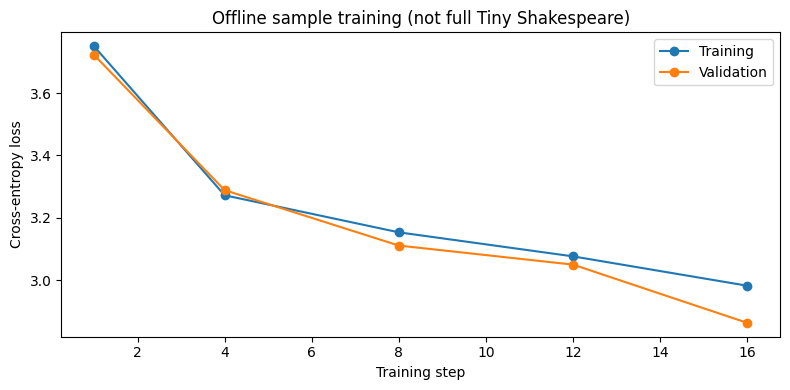

In [6]:
test_loss = average_loss(test_data, batches=8)
print('Held-out test loss:', round(test_loss, 4))
print('Perplexity:', round(math.exp(test_loss), 2))
if preview:
    print('These metrics describe the SHORT SAMPLE TEXT ONLY.')

plt.figure(figsize=(8, 4))
plt.plot(steps, train_losses, marker='o', label='Training')
plt.plot(steps, val_losses, marker='o', label='Validation')
plt.xlabel('Training step')
plt.ylabel('Cross-entropy loss')
plt.title('Offline sample training (not full Tiny Shakespeare)' if preview else 'Transformer training loss')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Generate text and check the attention mask

After a short run, generated text can still be noisy. The plot below shows that each position can attend only to earlier positions and itself.

Prompt: 'ROMEO:\n'
Generated text:

ROMEO:
nodossn: tnehisoh ttthor!sath be la t u?e,us thoo thOso tpws wo the! n t L,oi ththase, t h t' rtgtu eO E ul s lr iHhw, tuL s ut tiT tn, a wHtr  Mtr or  tThlUer s is haaossn'hiiub i


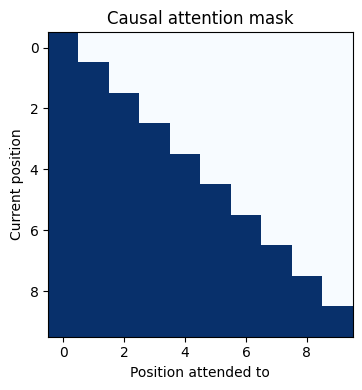

In [7]:
prompt = 'ROMEO:\n'
if any(ch not in to_id for ch in prompt):
    prompt = text[:8]
input_ids = torch.tensor([encode(prompt)], dtype=torch.long)
result = model.generate(input_ids, number=180 if preview else 300)
print('Prompt:', repr(prompt))
print('Generated text:\n')
print(decode(result[0].tolist()))

mask = np.tril(np.ones((10, 10)))
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(mask, cmap='Blues', vmin=0, vmax=1)
ax.set_xlabel('Position attended to')
ax.set_ylabel('Current position')
ax.set_title('Causal attention mask')
plt.tight_layout()
plt.show()

## What to upload to GitHub

Upload this executed notebook (`.ipynb`) and the README file. Its outputs are embedded in the notebook, so GitHub can display them. Run the notebook with the full Tiny Shakespeare text before presenting its metrics as actual experiment results.